In [1]:
import os
import random
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
warnings.filterwarnings("ignore")
print("citations: feature and validation pipeline reuses tutorial.ipynb and tutorial_improved_v1_4.ipynb and tutorial_improved_v2_0.ipynb and tutorial_improved_v2_5.ipynb")
print("v3.0 design: extend v2.6 features with EXT poly plus age plus employed interactions and ratio plus missing features, probe LightGBM deep variant and XGBoost and HGB in ablation, full 5-fold seed-averaged CV, OOF-selected blend")
SEED = 42
N_SPLITS = 5
SMOOTHING = 60
SEEDS = [42, 43, 44, 45, 46]
CAT8 = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
        "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
LGBM_BIG = dict(n_estimators=1500, learning_rate=0.02, num_leaves=63, min_child_samples=80,
                feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1,
                lambda_l1=0.1, lambda_l2=1.0, deterministic=True, verbose=-1)
XGB_P = dict(n_estimators=1000, learning_rate=0.02, max_leaves=31, grow_policy="lossguide",
             tree_method="hist", min_child_weight=80, colsample_bytree=0.8, subsample=0.9,
             reg_alpha=0.1, reg_lambda=1.0, eval_metric="auc", verbosity=0)
HGB_A = dict(learning_rate=0.035, max_iter=700, max_leaf_nodes=31, min_samples_leaf=80, l2_regularization=2.0)
HGB_C = dict(learning_rate=0.03, max_iter=1000, max_leaf_nodes=63, min_samples_leaf=50, l2_regularization=2.0)
LGBM_P = dict(n_estimators=1000, learning_rate=0.02, num_leaves=31, min_child_samples=80,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l1=0.1, lambda_l2=1.0, deterministic=True, verbose=-1)
np.random.seed(SEED)
random.seed(SEED)
print("pandas", pd.__version__, "sklearn", __import__("sklearn").__version__, "lgbm", lgb.__version__)
print("CAT8 =", CAT8)
print("SEEDS =", SEEDS)

citations: feature and validation pipeline reuses tutorial.ipynb and tutorial_improved_v1_4.ipynb and tutorial_improved_v2_0.ipynb and tutorial_improved_v2_5.ipynb
v3.0 design: extend v2.6 features with EXT poly plus age plus employed interactions and ratio plus missing features, probe LightGBM deep variant and XGBoost and HGB in ablation, full 5-fold seed-averaged CV, OOF-selected blend
pandas 3.0.6 sklearn 1.9.1 lgbm 4.7.0
CAT8 = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
SEEDS = [42, 43, 44, 45, 46]


In [2]:
current_dir = Path.cwd()
input_dir = current_dir / "input"
train_file = input_dir / "train.csv"
test_file = input_dir / "test.csv"
sample_sub_file = input_dir / "sample_submission.csv"
assert train_file.exists()
assert test_file.exists()
assert sample_sub_file.exists()
train_raw = pd.read_csv(train_file)
test_raw = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
print("train:", train_raw.shape, "test:", test_raw.shape, "sample_sub:", sample_sub.shape)
assert "TARGET" in train_raw.columns and "TARGET" not in test_raw.columns
assert list(sample_sub.columns) == ["SK_ID_CURR", "TARGET"]
assert sample_sub["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
assert len(test_raw) == 61500
y = train_raw["TARGET"].astype(int)
X_raw = train_raw.drop(columns="TARGET")
X_test_raw = test_raw.copy()
print("TARGET mean:", float(y.mean()))
print(y.value_counts().to_string())
print(train_raw.dtypes.value_counts())

train: (171202, 34) test: (61500, 33) sample_sub: (61500, 2)
TARGET mean: 0.08072919708881905
TARGET
0    157381
1     13821
float64    16
int64      10
str         8
Name: count, dtype: int64


Top-15 missing fractions:
EXT_SOURCE_1                  0.694665
OWN_CAR_AGE                   0.659992
EXT_SOURCE_3                  0.318840
AMT_REQ_CREDIT_BUREAU_MON     0.135022
AMT_REQ_CREDIT_BUREAU_QRT     0.135022
AMT_REQ_CREDIT_BUREAU_HOUR    0.135022
AMT_REQ_CREDIT_BUREAU_YEAR    0.135022
EXT_SOURCE_2                  0.002155
CNT_FAM_MEMBERS               0.000012
SK_ID_CURR                    0.000000
NAME_CONTRACT_TYPE            0.000000
CODE_GENDER                   0.000000
AMT_INCOME_TOTAL              0.000000
CNT_CHILDREN                  0.000000
AMT_ANNUITY                   0.000000


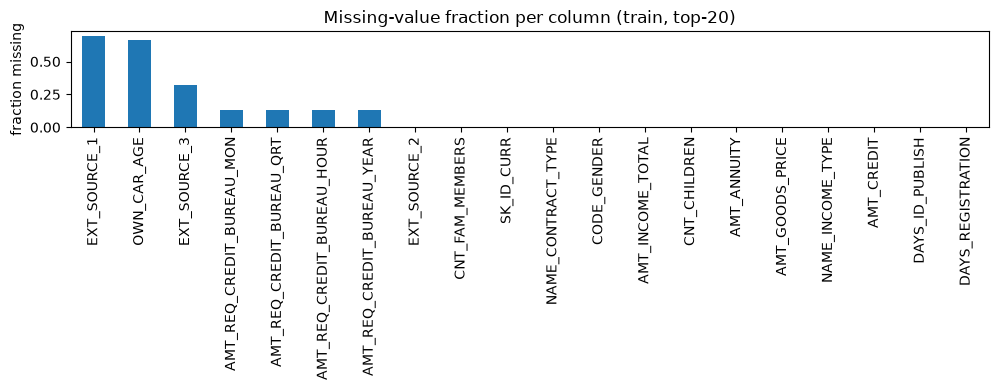

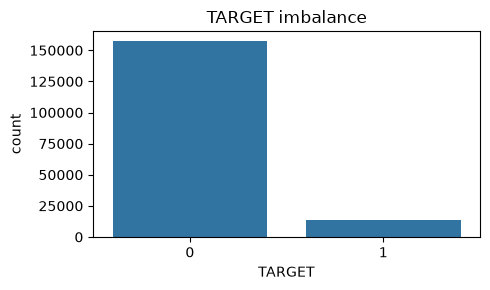

DAYS_EMPLOYED anomaly share train: 0.18047686358804219 test: 0.17178861788617886


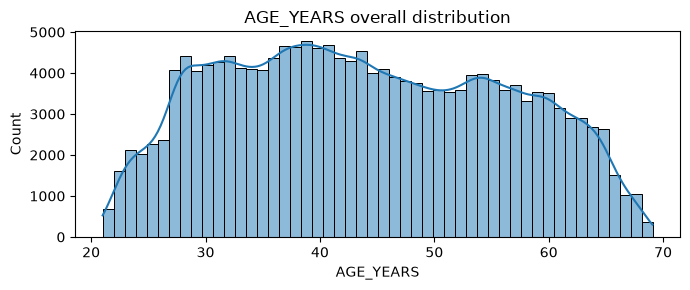

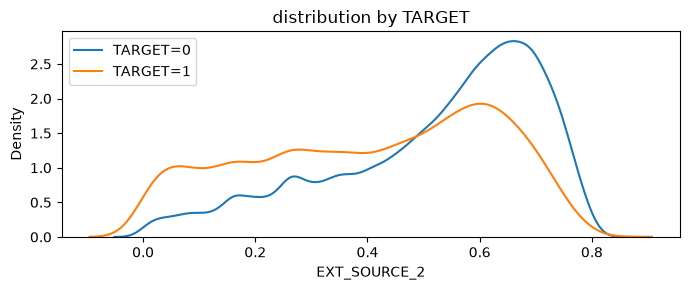

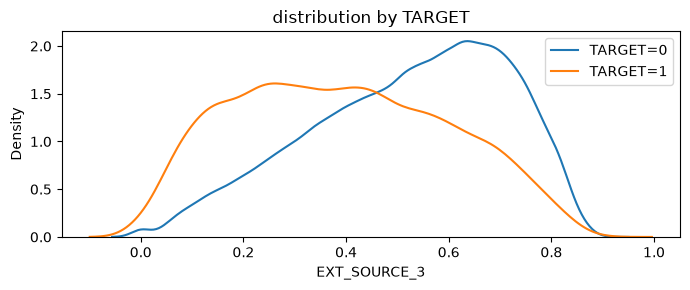

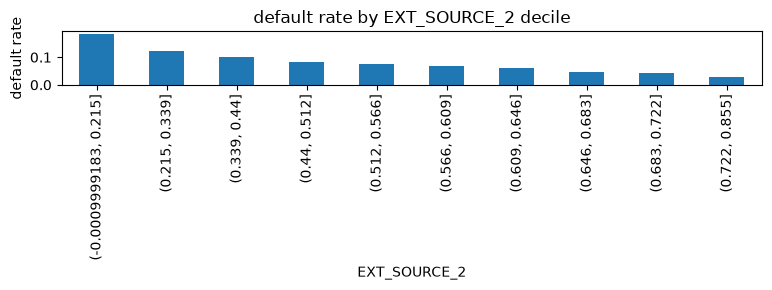

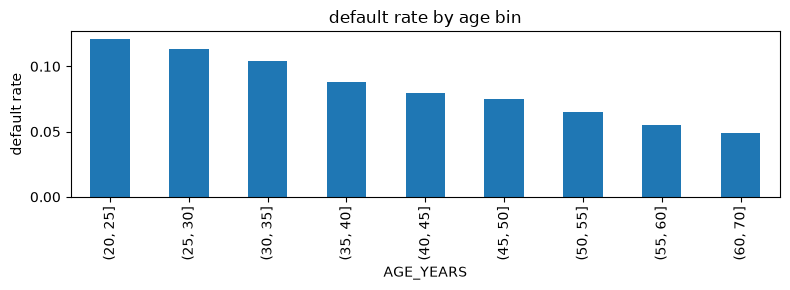

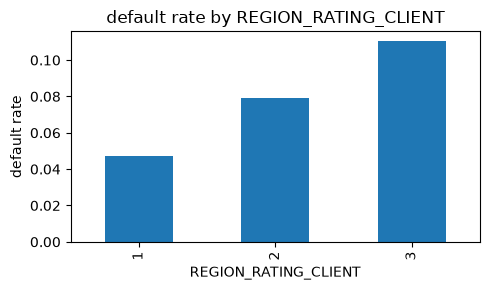

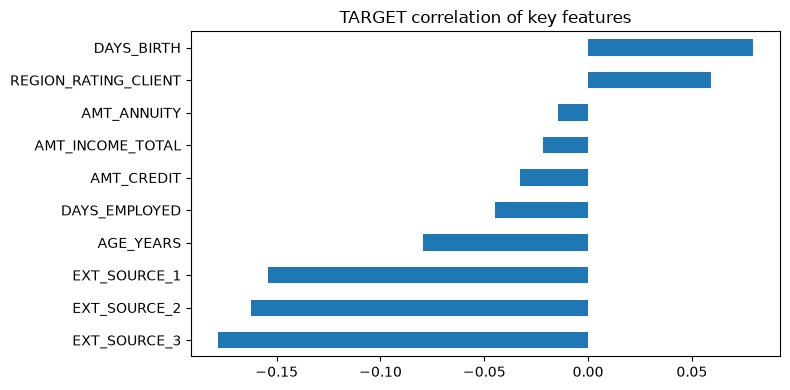

key feature correlations with TARGET:
EXT_SOURCE_3           -0.1783
EXT_SOURCE_2           -0.1626
EXT_SOURCE_1           -0.1540
AGE_YEARS              -0.0795
DAYS_EMPLOYED          -0.0446
AMT_CREDIT             -0.0327
AMT_INCOME_TOTAL       -0.0216
AMT_ANNUITY            -0.0146
REGION_RATING_CLIENT    0.0590
DAYS_BIRTH              0.0795


In [3]:
miss = train_raw.isna().mean().sort_values(ascending=False)
print("Top-15 missing fractions:")
print(miss.head(15).to_string())
plt.figure(figsize=(10, 4))
miss.head(20).plot(kind="bar")
plt.title("Missing-value fraction per column (train, top-20)")
plt.ylabel("fraction missing")
plt.tight_layout()
plt.show()
plt.figure(figsize=(5, 3))
sns.countplot(x=y)
plt.title("TARGET imbalance")
plt.tight_layout()
plt.show()
anio_tr = (train_raw["DAYS_EMPLOYED"] == 365243).mean()
anio_te = (test_raw["DAYS_EMPLOYED"] == 365243).mean()
print("DAYS_EMPLOYED anomaly share train:", float(anio_tr), "test:", float(anio_te))
train_plot = train_raw.copy()
train_plot["AGE_YEARS"] = -train_plot["DAYS_BIRTH"] / 365.25
plt.figure(figsize=(7, 3))
sns.histplot(train_plot["AGE_YEARS"].dropna(), bins=50, kde=True)
plt.title("AGE_YEARS overall distribution")
plt.tight_layout()
plt.show()
for c in ["EXT_SOURCE_2", "EXT_SOURCE_3"]:
    plt.figure(figsize=(7, 3))
    for tgt, lab in [(0, "TARGET=0"), (1, "TARGET=1")]:
        sns.kdeplot(train_plot.loc[train_plot["TARGET"] == tgt, c].dropna(), label=lab)
    plt.title("distribution by TARGET")
    plt.legend()
    plt.tight_layout()
    plt.show()

ext_sample = train_raw["EXT_SOURCE_2"].dropna()
pd.cut(ext_sample, bins=10).value_counts().sort_index()
train_plot = train_raw.copy()
train_plot["AGE_YEARS"] = -train_plot["DAYS_BIRTH"] / 365.25
ext_bins = pd.qcut(train_plot["EXT_SOURCE_2"].dropna(), q=10, duplicates="drop")
dr = train_plot.dropna(subset=["EXT_SOURCE_2"]).groupby(ext_bins, observed=True)["TARGET"].mean()
plt.figure(figsize=(8, 3))
dr.plot(kind="bar")
plt.title("default rate by EXT_SOURCE_2 decile")
plt.ylabel("default rate")
plt.tight_layout()
plt.show()
age_bins = pd.cut(train_plot["AGE_YEARS"].dropna(), bins=[20, 25, 30, 35, 40, 45, 50, 55, 60, 70])
adr = train_plot.dropna(subset=["AGE_YEARS"]).groupby(age_bins, observed=True)["TARGET"].mean()
plt.figure(figsize=(8, 3))
adr.plot(kind="bar")
plt.title("default rate by age bin")
plt.ylabel("default rate")
plt.tight_layout()
plt.show()
plt.figure(figsize=(5, 3))
train_plot.groupby("REGION_RATING_CLIENT")["TARGET"].mean().plot(kind="bar")
plt.title("default rate by REGION_RATING_CLIENT")
plt.ylabel("default rate")
plt.tight_layout()
plt.show()
key_feats = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EXT_SOURCE_MEAN",
             "AGE_YEARS", "EMPLOYED_YEARS", "AMT_CREDIT", "AMT_ANNUITY",
             "AMT_INCOME_TOTAL", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
             "DAYS_BIRTH", "DAYS_EMPLOYED", "REGION_RATING_CLIENT",
             "BUREAU_REQUEST_TOTAL", "TARGET"]
num_only = train_plot.select_dtypes(include=np.number)
num_key = [c for c in key_feats if c in num_only.columns]
corr = num_key_stats = num_only[num_key].corr()["TARGET"].drop("TARGET").sort_values()
plt.figure(figsize=(8, 4))
corr.plot(kind="barh")
plt.title("TARGET correlation of key features")
plt.tight_layout()
plt.show()
print("key feature correlations with TARGET:")
print(corr.round(4).to_string())


In [4]:
def safe_divide(a, b):
    return a / b.replace(0, np.nan)


def add_features_v2(df):
    df = df.copy()
    if "DAYS_EMPLOYED" in df.columns:
        df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype("int8")
        df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
    if "DAYS_BIRTH" in df.columns:
        df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
    if "DAYS_EMPLOYED" in df.columns:
        df["EMPLOYED_YEARS"] = -df["DAYS_EMPLOYED"] / 365.25
    if {"DAYS_BIRTH", "DAYS_EMPLOYED"}.issubset(df.columns):
        df["EMPLOYED_AGE_RATIO"] = safe_divide(-df["DAYS_EMPLOYED"], -df["DAYS_BIRTH"])
    if {"DAYS_REGISTRATION", "DAYS_BIRTH"}.issubset(df.columns):
        df["REGISTRATION_AGE_RATIO"] = safe_divide(-df["DAYS_REGISTRATION"], -df["DAYS_BIRTH"])
    if "DAYS_REGISTRATION" in df.columns:
        df["REGISTRATION_YEARS"] = -df["DAYS_REGISTRATION"] / 365.25
    if "DAYS_ID_PUBLISH" in df.columns:
        df["ID_DOCUMENT_YEARS"] = -df["DAYS_ID_PUBLISH"] / 365.25
    if "DAYS_LAST_PHONE_CHANGE" in df.columns:
        df["PHONE_CHANGE_YEARS"] = -df["DAYS_LAST_PHONE_CHANGE"] / 365.25
    if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CREDIT_INCOME_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_INCOME_TOTAL"])
        df["INCOME_CREDIT_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_CREDIT"])
    if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["ANNUITY_INCOME_RATIO"] = safe_divide(df["AMT_ANNUITY"], df["AMT_INCOME_TOTAL"])
        df["INCOME_ANNUITY_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_ANNUITY"])
    if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(df.columns):
        df["CREDIT_ANNUITY_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_ANNUITY"])
    if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(df.columns):
        df["GOODS_CREDIT_RATIO"] = safe_divide(df["AMT_GOODS_PRICE"], df["AMT_CREDIT"])
        df["CREDIT_GOODS_GAP"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["INCOME_PER_FAMILY"] = safe_divide(df["AMT_INCOME_TOTAL"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    if {"AMT_CREDIT", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CREDIT_PER_FAMILY"] = safe_divide(df["AMT_CREDIT"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if ext:
        df["EXT_SOURCE_MEAN"] = df[ext].mean(axis=1)
        df["EXT_SOURCE_MEDIAN"] = df[ext].median(axis=1)
        df["EXT_SOURCE_MIN"] = df[ext].min(axis=1)
        df["EXT_SOURCE_MAX"] = df[ext].max(axis=1)
        df["EXT_SOURCE_RANGE"] = df[ext].max(axis=1) - df[ext].min(axis=1)
        df["EXT_SOURCE_STD"] = df[ext].std(axis=1)
        df["EXT_SOURCE_MISSING"] = df[ext].isna().sum(axis=1)
        for c in ext:
            df[c + "_SQ"] = df[c] ** 2
            df[c + "_CUBE"] = df[c] ** 3
        for i in range(len(ext)):
            for j in range(i + 1, len(ext)):
                a, b = ext[i], ext[j]
                df[a + "_" + b + "_PROD"] = df[a] * df[b]
                df[a + "_" + b + "_DIFF"] = df[a] - df[b]
                df[a + "_" + b + "_ABS_DIFF"] = (df[a] - df[b]).abs()
                df[a + "_" + b + "_RATIO"] = safe_divide(df[a], df[b])
    bureau = [c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU_")]
    if bureau:
        df["BUREAU_REQUEST_TOTAL"] = df[bureau].sum(axis=1, min_count=1)
        df["BUREAU_REQUEST_MEAN"] = df[bureau].mean(axis=1)
        df["BUREAU_REQUEST_MAX"] = df[bureau].max(axis=1)
        df["BUREAU_REQUEST_MISSING"] = df[bureau].isna().sum(axis=1)
    if {"CNT_CHILDREN", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CHILDREN_FAMILY_RATIO"] = safe_divide(df["CNT_CHILDREN"], df["CNT_FAM_MEMBERS"].clip(lower=1))
        df["ADULTS_IN_FAMILY"] = df["CNT_FAM_MEMBERS"] - df["CNT_CHILDREN"]
    contact = [c for c in ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE",
                           "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"] if c in df.columns]
    if contact:
        df["CONTACT_FLAG_SUM"] = df[contact].sum(axis=1)
    df["TOTAL_MISSING"] = df.isna().sum(axis=1)
    df["MISSING_RATIO"] = df.isna().mean(axis=1)
    for col, new in [("AMT_INCOME_TOTAL", "LOG_AMT_INCOME_TOTAL"),
                     ("AMT_CREDIT", "LOG_AMT_CREDIT"),
                     ("AMT_ANNUITY", "LOG_AMT_ANNUITY"),
                     ("AMT_GOODS_PRICE", "LOG_AMT_GOODS_PRICE")]:
        if col in df.columns:
            df[new] = np.log1p(df[col].clip(lower=0))
    if {"AMT_ANNUITY", "AMT_CREDIT"}.issubset(df.columns):
        df["ANNUITY_CREDIT_RATE"] = safe_divide(df["AMT_ANNUITY"], df["AMT_CREDIT"])
    if {"AMT_INCOME_TOTAL", "CNT_CHILDREN"}.issubset(df.columns):
        df["INCOME_PER_CHILD"] = safe_divide(df["AMT_INCOME_TOTAL"], (df["CNT_CHILDREN"] + 1))
    if "OWN_CAR_AGE" in df.columns:
        df["OWN_CAR_MISSING"] = df["OWN_CAR_AGE"].isna().astype("int8")
        df["OWN_CAR_DECADE"] = df["OWN_CAR_AGE"] / 10.0
    if "ORGANIZATION_TYPE" in df.columns:
        df["ORG_IS_XNA"] = (df["ORGANIZATION_TYPE"] == "XNA").astype("int8")
    if {"REGION_RATING_CLIENT", "REGION_POPULATION_RELATIVE"}.issubset(df.columns):
        df["RATING_POP_INTERACT"] = df["REGION_RATING_CLIENT"] * df["REGION_POPULATION_RELATIVE"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df

def add_row_features_v2_5(df):
    df = df.copy()
    if "AGE_YEARS" in df.columns:
        df["AGE_YEARS_SQ"] = df["AGE_YEARS"] ** 2
    if "EXT_SOURCE_MEAN" in df.columns:
        df["EXT_SOURCE_MEAN_SQ"] = df["EXT_SOURCE_MEAN"] ** 2
    if {"AMT_ANNUITY", "AMT_GOODS_PRICE"}.issubset(df.columns):
        df["ANNUITY_GOODS_RATIO"] = df["AMT_ANNUITY"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS", "CNT_CHILDREN"}.issubset(df.columns):
        adults = (df["CNT_FAM_MEMBERS"] - df["CNT_CHILDREN"]).clip(lower=1)
        df["INCOME_PER_ADULT"] = df["AMT_INCOME_TOTAL"] / adults
    if "INCOME_PER_FAMILY" in df.columns:
        df["LOG_INCOME_PER_FAMILY"] = np.log1p(df["INCOME_PER_FAMILY"].clip(lower=0))
    if {"EMPLOYED_YEARS", "AGE_YEARS"}.issubset(df.columns):
        df["EMPLOYED_AGE_INTERACT"] = df["EMPLOYED_YEARS"] * df["AGE_YEARS"]
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if ext:
        pat = pd.Series(np.zeros(len(df), dtype="int8"), index=df.index)
        for i, c in enumerate(ext):
            pat = pat + df[c].isna().astype("int8") * (2 ** i)
        df["EXT_MISS_PATTERN"] = pat.astype("int8")
    if "BUREAU_REQUEST_TOTAL" in df.columns:
        df["BUREAU_REQUEST_ANY"] = (df["BUREAU_REQUEST_TOTAL"].fillna(0) > 0).astype("int8")
    if {"OWN_CAR_AGE", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CAR_AGE_INCOME_INTERACT"] = df["OWN_CAR_AGE"] * df["AMT_INCOME_TOTAL"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df


def add_row_features_v3_0(df):
    df = df.copy()
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if len(ext) == 3:
        df["EXT_SOURCE_TRIPLE"] = df[ext[0]] * df[ext[1]] * df[ext[2]]
    if "AGE_YEARS" in df.columns and len(ext) > 0:
        for c in ext:
            df[c + "_AGE_PROD"] = df[c] * df["AGE_YEARS"]
            df[c + "_AGE_RATIO"] = safe_divide(df[c], df["AGE_YEARS"])
    if "EMPLOYED_YEARS" in df.columns and len(ext) > 0:
        for c in ext:
            df[c + "_EMPLOYED_PROD"] = df[c] * df["EMPLOYED_YEARS"]
    if "OCCUPATION_TYPE" in df.columns:
        df["OCC_IS_MISSING"] = df["OCCUPATION_TYPE"].isna().astype("int8")
    if {"AMT_INCOME_TOTAL", "AMT_ANNUITY"}.issubset(df.columns):
        df["INCOME_MINUS_ANNUITY"] = df["AMT_INCOME_TOTAL"] - df["AMT_ANNUITY"]
    if {"AMT_GOODS_PRICE", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["GOODS_INCOME_RATIO"] = safe_divide(df["AMT_GOODS_PRICE"], df["AMT_INCOME_TOTAL"])
    if {"BUREAU_REQUEST_TOTAL", "AMT_REQ_CREDIT_BUREAU_YEAR"}.issubset(df.columns):
        df["BUREAU_YEAR_SHARE"] = safe_divide(df["AMT_REQ_CREDIT_BUREAU_YEAR"], df["BUREAU_REQUEST_TOTAL"])
    if {"PHONE_CHANGE_YEARS", "AGE_YEARS"}.issubset(df.columns):
        df["PHONE_AGE_RATIO"] = safe_divide(df["PHONE_CHANGE_YEARS"], df["AGE_YEARS"])
    if {"AMT_CREDIT", "CNT_CHILDREN"}.issubset(df.columns):
        df["CREDIT_PER_CHILD"] = safe_divide(df["AMT_CREDIT"], df["CNT_CHILDREN"] + 1)
    if {"EXT_SOURCE_MEAN", "REGION_RATING_CLIENT"}.issubset(df.columns):
        df["EXT_MEAN_RATING_PROD"] = df["EXT_SOURCE_MEAN"] * df["REGION_RATING_CLIENT"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df

X_base = add_row_features_v2_5(add_features_v2(X_raw))
X_test_base = add_row_features_v2_5(add_features_v2(X_test_raw)).reindex(columns=X_base.columns, fill_value=np.nan)
X = add_row_features_v3_0(X_base)
X_test = add_row_features_v3_0(X_test_base).reindex(columns=X.columns, fill_value=np.nan)
print("X_base:", X_base.shape, "X_test_base:", X_test_base.shape)
print("X:", X.shape, "X_test:", X_test.shape)
assert list(X_base.columns) == list(X_test_base.columns)
assert list(X.columns) == list(X_test.columns)
assert X_base.shape == (171202, 103) and X_test_base.shape == (61500, 103)
assert X.shape == (171202, 120) and X_test.shape == (61500, 120)
assert X.shape[1] == X_base.shape[1] + 17
assert [c for c in X.columns if c not in X_base.columns] == [
    "EXT_SOURCE_TRIPLE",
    "EXT_SOURCE_1_AGE_PROD", "EXT_SOURCE_1_AGE_RATIO",
    "EXT_SOURCE_2_AGE_PROD", "EXT_SOURCE_2_AGE_RATIO",
    "EXT_SOURCE_3_AGE_PROD", "EXT_SOURCE_3_AGE_RATIO",
    "EXT_SOURCE_1_EMPLOYED_PROD", "EXT_SOURCE_2_EMPLOYED_PROD", "EXT_SOURCE_3_EMPLOYED_PROD",
    "OCC_IS_MISSING", "INCOME_MINUS_ANNUITY", "GOODS_INCOME_RATIO",
    "BUREAU_YEAR_SHARE", "PHONE_AGE_RATIO", "CREDIT_PER_CHILD", "EXT_MEAN_RATING_PROD"]
assert not np.isinf(X.select_dtypes(include=np.number).to_numpy()).any()
assert not np.isinf(X_test.select_dtypes(include=np.number).to_numpy()).any()
print("new v3.0 columns added:", X.shape[1] - X_base.shape[1])
print("numeric count:", len([c for c in X.columns if c not in CAT8]))


X_base: (171202, 103) X_test_base: (61500, 103)
X: (171202, 120) X_test: (61500, 120)
new v3.0 columns added: 17
numeric count: 112


In [5]:
def frequency_map(train_df, other_df, cols):
    out = other_df.copy()
    for c in cols:
        m = train_df[c].value_counts(dropna=False, normalize=True)
        out[c + "__FREQ"] = other_df[c].map(m).fillna(0.0)
    return out


def target_map(train_df, y_train, other_df, cols, smoothing=60):
    out = other_df.copy()
    gm = float(np.mean(y_train))
    for c in cols:
        tmp = pd.DataFrame({"x": train_df[c].astype(object).values, "y": np.asarray(y_train)})
        st = tmp.groupby("x", dropna=False)["y"].agg(["mean", "count"])
        sm = (st["mean"] * st["count"] + gm * smoothing) / (st["count"] + smoothing)
        out[c + "__TE"] = other_df[c].map(sm).fillna(gm).astype(float)
    return out


def groupby_fit(train_df, cat_cols, num_cols):
    maps = {}
    for c in cat_cols:
        key = train_df[c].astype(object)
        g = train_df.groupby(key, dropna=False)
        for n in num_cols:
            if n in train_df.columns:
                maps[(c, n)] = (g[n].mean(), float(train_df[n].mean()))
        sizes = g.size()
        maps[(c, "__SIZE__")] = (sizes, float(sizes.mean()))
    return maps


def groupby_apply(other_df, maps, cat_cols, num_cols):
    out = other_df.copy()
    for c in cat_cols:
        key = other_df[c].astype(object)
        for n in num_cols:
            if (c, n) in maps:
                m, glob = maps[(c, n)]
                out[c + "__GB_MEAN_" + n] = key.map(m).fillna(glob).astype(float)
        m, glob = maps[(c, "__SIZE__")]
        out[c + "__GB_SIZE"] = key.map(m).fillna(glob).astype(float)
    return out


def pair_key(df, a, b):
    return df[a].astype(object).astype(str) + "||" + df[b].astype(object).astype(str)


def pair_te_fit(train_df, y_train, pairs, smoothing=60):
    gm = float(np.mean(y_train))
    maps = {}
    for ab in pairs:
        a, b = ab
        key = pair_key(train_df, a, b)
        tmp = pd.DataFrame({"k": key.values, "y": np.asarray(y_train)})
        st = tmp.groupby("k")["y"].agg(["mean", "count"])
        sm = (st["mean"] * st["count"] + gm * smoothing) / (st["count"] + smoothing)
        maps[ab] = (sm, gm)
    return maps


def pair_te_apply(other_df, maps, pairs):
    out = other_df.copy()
    for ab in pairs:
        a, b = ab
        sm, gm = maps[ab]
        key = pair_key(other_df, a, b)
        out[a + "__X__" + b + "__PTE"] = key.map(sm).fillna(gm).astype(float)
    return out



cat_cols = [c for c in CAT8 if c in X.columns]
print("encoding categoricals:", cat_cols)
assert len(cat_cols) == 8
print("smoothing:", SMOOTHING)


encoding categoricals: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
smoothing: 60


In [6]:

t_abl = time.time()
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
splits3 = list(skf3.split(X, y))


def encode_pair(X_tr, X_va, y_tr):
    tr_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_tr, cat_cols), cat_cols, smoothing=SMOOTHING)
    va_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_va, cat_cols), cat_cols, smoothing=SMOOTHING)
    add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
    tr_n = pd.concat([X_tr.drop(columns=cat_cols), tr_e[add_c]], axis=1)
    va_n = pd.concat([X_va.drop(columns=cat_cols), va_e[add_c]], axis=1)
    return tr_n, va_n


def encode_all(X_tr, y_tr, others):
    tr_e = target_map(X_tr, y_tr, frequency_map(X_tr, X_tr, cat_cols), cat_cols, smoothing=SMOOTHING)
    add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
    out = [pd.concat([X_tr.drop(columns=cat_cols), tr_e[add_c]], axis=1)]
    for other in others:
        other_e = target_map(X_tr, y_tr, frequency_map(X_tr, other, cat_cols), cat_cols, smoothing=SMOOTHING)
        out.append(pd.concat([other.drop(columns=cat_cols), other_e[add_c]], axis=1))
    return out


def eval_variant(name, Xa, make_model, impute):
    oof = np.zeros(len(Xa))
    fl = []
    for tr_idx, va_idx in splits3:
        X_tr = Xa.iloc[tr_idx].copy()
        X_va = Xa.iloc[va_idx].copy()
        y_tr = y.iloc[tr_idx]
        y_va = y.iloc[va_idx]
        tr_n, va_n = encode_pair(X_tr, X_va, y_tr)
        if impute:
            imp = SimpleImputer(strategy="median", add_indicator=True)
            tr_n = imp.fit_transform(tr_n)
            va_n = imp.transform(va_n)
        mdl = make_model()
        mdl.fit(tr_n, y_tr)
        p = mdl.predict_proba(va_n)[:, 1]
        oof[va_idx] = p
        fl.append(roc_auc_score(y_va, p))
    s = float(roc_auc_score(y, oof))
    print("ablation", name, "folds", [round(v, 6) for v in fl], "OOF=", round(s, 6), flush=True)
    return s


s_base = eval_variant("base_lgbm", X_base, lambda: lgb.LGBMClassifier(**LGBM_P, random_state=SEED), False)
s_new = eval_variant("new_lgbm", X, lambda: lgb.LGBMClassifier(**LGBM_P, random_state=SEED), False)
s_big = eval_variant("new_lgbm_big", X, lambda: lgb.LGBMClassifier(**LGBM_BIG, random_state=SEED), False)
s_xgb = eval_variant("new_xgb", X, lambda: XGBClassifier(**XGB_P, random_state=SEED), False)
s_hgb = eval_variant("new_hgb", X, lambda: HistGradientBoostingClassifier(**HGB_A, random_state=SEED), True)
feat_delta = s_new - s_base
USE_NEW = bool(feat_delta >= 0)
lgb_best = max(s_new, s_big)
LGBM_PARAMS_FINAL = dict(LGBM_BIG) if (USE_NEW and s_big >= s_new) else dict(LGBM_P)
if not USE_NEW:
    LGBM_PARAMS_FINAL = dict(LGBM_P)
ref = lgb_best if USE_NEW else s_base
USE_XGB = bool(s_xgb >= ref)
USE_HGB = bool(s_hgb >= ref)
print("decision: feat_delta=", round(float(feat_delta), 6), "USE_NEW=", USE_NEW)
print("decision: LGBM_PARAMS_FINAL=", LGBM_PARAMS_FINAL)
print("decision: xgb_delta=", round(float(s_xgb - ref), 6), "USE_XGB=", USE_XGB)
print("decision: hgb_delta=", round(float(s_hgb - ref), 6), "USE_HGB=", USE_HGB)
print("ablation wall time:", round(time.time() - t_abl, 1), "s")


ablation base_lgbm folds [0.758996, 0.759601, 0.75696] OOF= 0.758503


ablation new_lgbm folds [0.758877, 0.75883, 0.757235] OOF= 0.7583


ablation new_lgbm_big folds [0.75405, 0.754278, 0.752198] OOF= 0.753484


ablation new_xgb folds [0.760139, 0.758698, 0.758416] OOF= 0.759064


ablation new_hgb folds [0.75475, 0.753326, 0.755549] OOF= 0.754479


decision: feat_delta= -0.000203 USE_NEW= False
decision: LGBM_PARAMS_FINAL= {'n_estimators': 1000, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 80, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l1': 0.1, 'lambda_l2': 1.0, 'deterministic': True, 'verbose': -1}
decision: xgb_delta= 0.000561 USE_XGB= True
decision: hgb_delta= -0.004024 USE_HGB= False
ablation wall time: 261.1 s


In [7]:

t_full = time.time()
XA = X if USE_NEW else X_base
TA = X_test if USE_NEW else X_test_base
specs = [("lgbm", lambda s: lgb.LGBMClassifier(**LGBM_PARAMS_FINAL, random_state=s))]
if USE_XGB:
    specs.append(("xgb", lambda s: XGBClassifier(**XGB_P, random_state=s)))
if USE_HGB:
    specs.append(("hgb", lambda s: HistGradientBoostingClassifier(**HGB_A, random_state=s)))
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
NS = len(SEEDS)
NF = N_SPLITS
oof = {name: np.zeros(len(XA)) for name, _ in specs}
testp = {name: np.zeros(len(TA)) for name, _ in specs}
fold_aucs = {name: [] for name, _ in specs}
for fold, (tr_idx, va_idx) in enumerate(skf.split(XA, y), 1):
    t0 = time.time()
    X_tr = XA.iloc[tr_idx].copy()
    X_va = XA.iloc[va_idx].copy()
    X_te = TA.copy()
    y_tr = y.iloc[tr_idx]
    y_va = y.iloc[va_idx]
    tr_n, va_n, te_n = encode_all(X_tr, y_tr, [X_va, X_te])
    need_impute = any(name == "hgb" for name, _ in specs)
    if need_impute:
        imp = SimpleImputer(strategy="median", add_indicator=True)
        tr_i = imp.fit_transform(tr_n)
        va_i = imp.transform(va_n)
        te_i = imp.transform(te_n)
    for name, make in specs:
        for s in SEEDS:
            m = make(s).fit(tr_n if name != "hgb" else tr_i, y_tr)
            oof[name][va_idx] += m.predict_proba(va_n if name != "hgb" else va_i)[:, 1] / NS
            testp[name] += m.predict_proba(te_n if name != "hgb" else te_i)[:, 1] / (NF * NS)
        fa = roc_auc_score(y_va, oof[name][va_idx])
        fold_aucs[name].append(fa)
    print("fold", fold, "time", round(time.time() - t0, 1), "s", flush=True)
    for name, _ in specs:
        print("  ", name, "fold AUC=", round(float(fold_aucs[name][-1]), 6), flush=True)
aucs = {}
for name, _ in specs:
    aucs[name] = float(roc_auc_score(y, oof[name]))
    print(name, "OOF AUC=", round(aucs[name], 6), "folds", [round(v, 6) for v in fold_aucs[name]])
if USE_NEW:
    assert XA.shape[1] == 120
else:
    assert XA.shape[1] == 103
print("full run wall time:", round(time.time() - t_full, 1), "s")


fold 1 time 164.3 s


   lgbm fold AUC= 0.757564


   xgb fold AUC= 0.758635


fold 2 time 168.9 s


   lgbm fold AUC= 0.763843


...

   xgb fold AUC= 0.757674


fold 5 time 163.1 s


   lgbm fold AUC= 0.762534


   xgb fold AUC= 0.761778


lgbm OOF AUC= 0.761453 folds [0.757564, 0.763843, 0.766511, 0.757017, 0.762534]
xgb OOF AUC= 0.76144 folds [0.758635, 0.762889, 0.76642, 0.757674, 0.761778]
full run wall time: 841.3 s


In [8]:

from itertools import combinations

names = [name for name, _ in specs]
print("single-model OOF AUCs:")
for name in names:
    print("  ", name, round(aucs[name], 6))
best_score = -1.0
best_w = {}
for name in names:
    if aucs[name] > best_score:
        best_score = aucs[name]
        best_w = {name: 1.0, **{n2: 0.0 for n2 in names if n2 != name}}
for n1, n2 in combinations(names, 2):
    for w in np.arange(0, 1.0001, 0.05):
        s = roc_auc_score(y, w * oof[n1] + (1 - w) * oof[n2])
        if s > best_score:
            best_score = float(s)
            best_w = {n: 0.0 for n in names}
            best_w[n1] = float(w)
            best_w[n2] = float(1 - w)
if len(names) >= 3:
    for n1, n2, n3 in combinations(names, 3):
        for w1 in np.arange(0, 1.0001, 0.1):
            for w2 in np.arange(0, 1.0001 - w1, 0.1):
                w3 = 1.0 - w1 - w2
                s = roc_auc_score(y, w1 * oof[n1] + w2 * oof[n2] + w3 * oof[n3])
                if s > best_score:
                    best_score = float(s)
                    best_w = {n: 0.0 for n in names}
                    best_w[n1] = float(w1)
                    best_w[n2] = float(w2)
                    best_w[n3] = float(w3)
OOF_AUC = float(best_score)
print("best weights:", best_w)
print("blend OOF AUC=", round(OOF_AUC, 6))
final_pred = np.zeros(len(TA))
for n in names:
    final_pred = final_pred + best_w.get(n, 0.0) * testp[n]
final_pred = np.clip(final_pred, 0, 1)
print("final_pred describe:")
print(pd.Series(final_pred).describe().to_string())


single-model OOF AUCs:
   lgbm 0.761453
   xgb 0.76144


best weights: {'lgbm': 0.5, 'xgb': 0.5}
blend OOF AUC= 0.76198
final_pred describe:
count    61500.000000
mean         0.093011
std          0.093508
min          0.002606
25%          0.030487
50%          0.060051
75%          0.120377
max          0.764328


In [9]:
output_dir = current_dir / "output"
output_dir.mkdir(exist_ok=True)
output_file = output_dir / "submission_improved_v3_0.csv"
submission = sample_sub.copy()
submission["TARGET"] = final_pred
assert submission["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
submission.to_csv(output_file, index=False, lineterminator="\n", encoding="utf-8")
print("wrote:", str(output_file))
chk = pd.read_csv(output_file)
assert list(chk.columns) == ["SK_ID_CURR", "TARGET"]
assert len(chk) == 61500
assert chk["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
assert chk["SK_ID_CURR"].equals(sample_sub["SK_ID_CURR"])
assert chk["TARGET"].isna().sum() == 0
assert ((chk["TARGET"] >= 0) & (chk["TARGET"] <= 1)).all()
raw = open(output_file, "rb").read()
assert b"\r" not in raw
assert raw.split(b"\n")[0].strip() == b"SK_ID_CURR,TARGET"
print("CSV validation passed: columns SK_ID_CURR TARGET, 61500 rows, IDs match, no NaN, probs in range 0 to 1, Unix newlines")
print("v3.0 blend OOF AUC:", round(OOF_AUC, 6), "weights:", best_w)
print(chk.head().to_string(index=False))
print(chk["TARGET"].describe().to_string())

wrote: C:\Users\sidha\Documents\visualcode\Competition\output\submission_improved_v3_0.csv
CSV validation passed: columns SK_ID_CURR TARGET, 61500 rows, IDs match, no NaN, probs in range 0 to 1, Unix newlines
v3.0 blend OOF AUC: 0.76198 weights: {'lgbm': 0.5, 'xgb': 0.5}
 SK_ID_CURR   TARGET
     171202 0.032997
     171203 0.184394
     171204 0.167213
     171205 0.113443
     171206 0.224822
count    61500.000000
mean         0.093011
std          0.093508
min          0.002606
25%          0.030487
50%          0.060051
75%          0.120377
max          0.764328
